In [1]:
# Imports
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as plticker
import numpy as np

from _utils.fig2_bures_approx_bound import (
    BOUND_FNS,
    compute_KL,
    compute_gmm_marginals,
    contour,
    contour_diag,
    create_gmm,
    diag_gmm,
    fmt_radians_for_path,
    pi_formatter,
)

# Global plotting and save controls.
figure_dpi = 300
save_figures = True
plots_dir = Path('../data/generated_plots') / 'rotation_bound'
plots_dir.mkdir(parents=True, exist_ok=True)

## Experiment configuration

In [2]:
# Gaussian pair parameters
# Angle between the two Gaussians (cov2 is cov1 rotated by this angle).
# Run the notebook once per angle of the paper: np.pi/2 (orthogonal), np.pi/3 and np.pi/4
# (worst case). Each run writes its figures to rotation_bound/<angle>pi/.
initial_pair_angle = np.pi/2

base_covariance = np.array([[0.07, 0.0], [0.0, 1.0]], dtype=float) # Base covariance before trace normalization.
cov2_scale = np.eye(2) # Optional covariance scaling applied before rotating cov2.
means = [[2.5, 2.5], [2.5, 2.5]] # both components are centered together to focus on covariance effects

# Plotting: Rotation grid and small gaussians snapshot grid resolution.
n_angle_steps = 40      # number of steps in [0, pi/2] before the +1 adjustment
plot_steps = 4         # controls the displayed (plot_steps+1) x (plot_steps+1) snapshot grid

# Bound
A = np.eye(2) # Linear map applied before rotation Q, set to identity for no linear map
bounds_to_plot = ['mi_only'] # Bound variants to compute and plot; keys must exist in BOUND_FNS
numerical_tol = 3e-3 # tolerance for bound-validity checks against actual_error


## Setup Gaussians at different rotations

In [3]:
# Derived experiment setup

# Normalize the configured base covariance by trace.
cov1 = base_covariance / np.trace(base_covariance)

# Construct cov2 as a rotated/scaled copy of cov1.
rotate = np.array(
    [[np.cos(initial_pair_angle), -np.sin(initial_pair_angle)], [np.sin(initial_pair_angle), np.cos(initial_pair_angle)]],
    dtype=float,
)
cov2 = rotate @ cov2_scale @ cov1 @ cov2_scale.T @ rotate.T
cov2 = cov2 / np.trace(cov2)

mpl.rcParams['figure.dpi'] = figure_dpi

# Output folder keyed by the initial covariance-pair angle.
angle_folder = f"{fmt_radians_for_path(float(initial_pair_angle))}pi"
save_dir = plots_dir / angle_folder
if save_figures:
    save_dir.mkdir(parents=True, exist_ok=True)

# File tag shared by saved figures.
file_tag = f'init_{angle_folder}rad'

# Derived grid arrays.
plot_every_i_step = int(n_angle_steps / plot_steps)
steps = n_angle_steps + 1
angles = np.linspace(0, np.pi / 2, num=steps) +  initial_pair_angle


Saved: ../data/generated_plots/rotation_bound/0.5pi/rotating_gaussians_grid.pdf


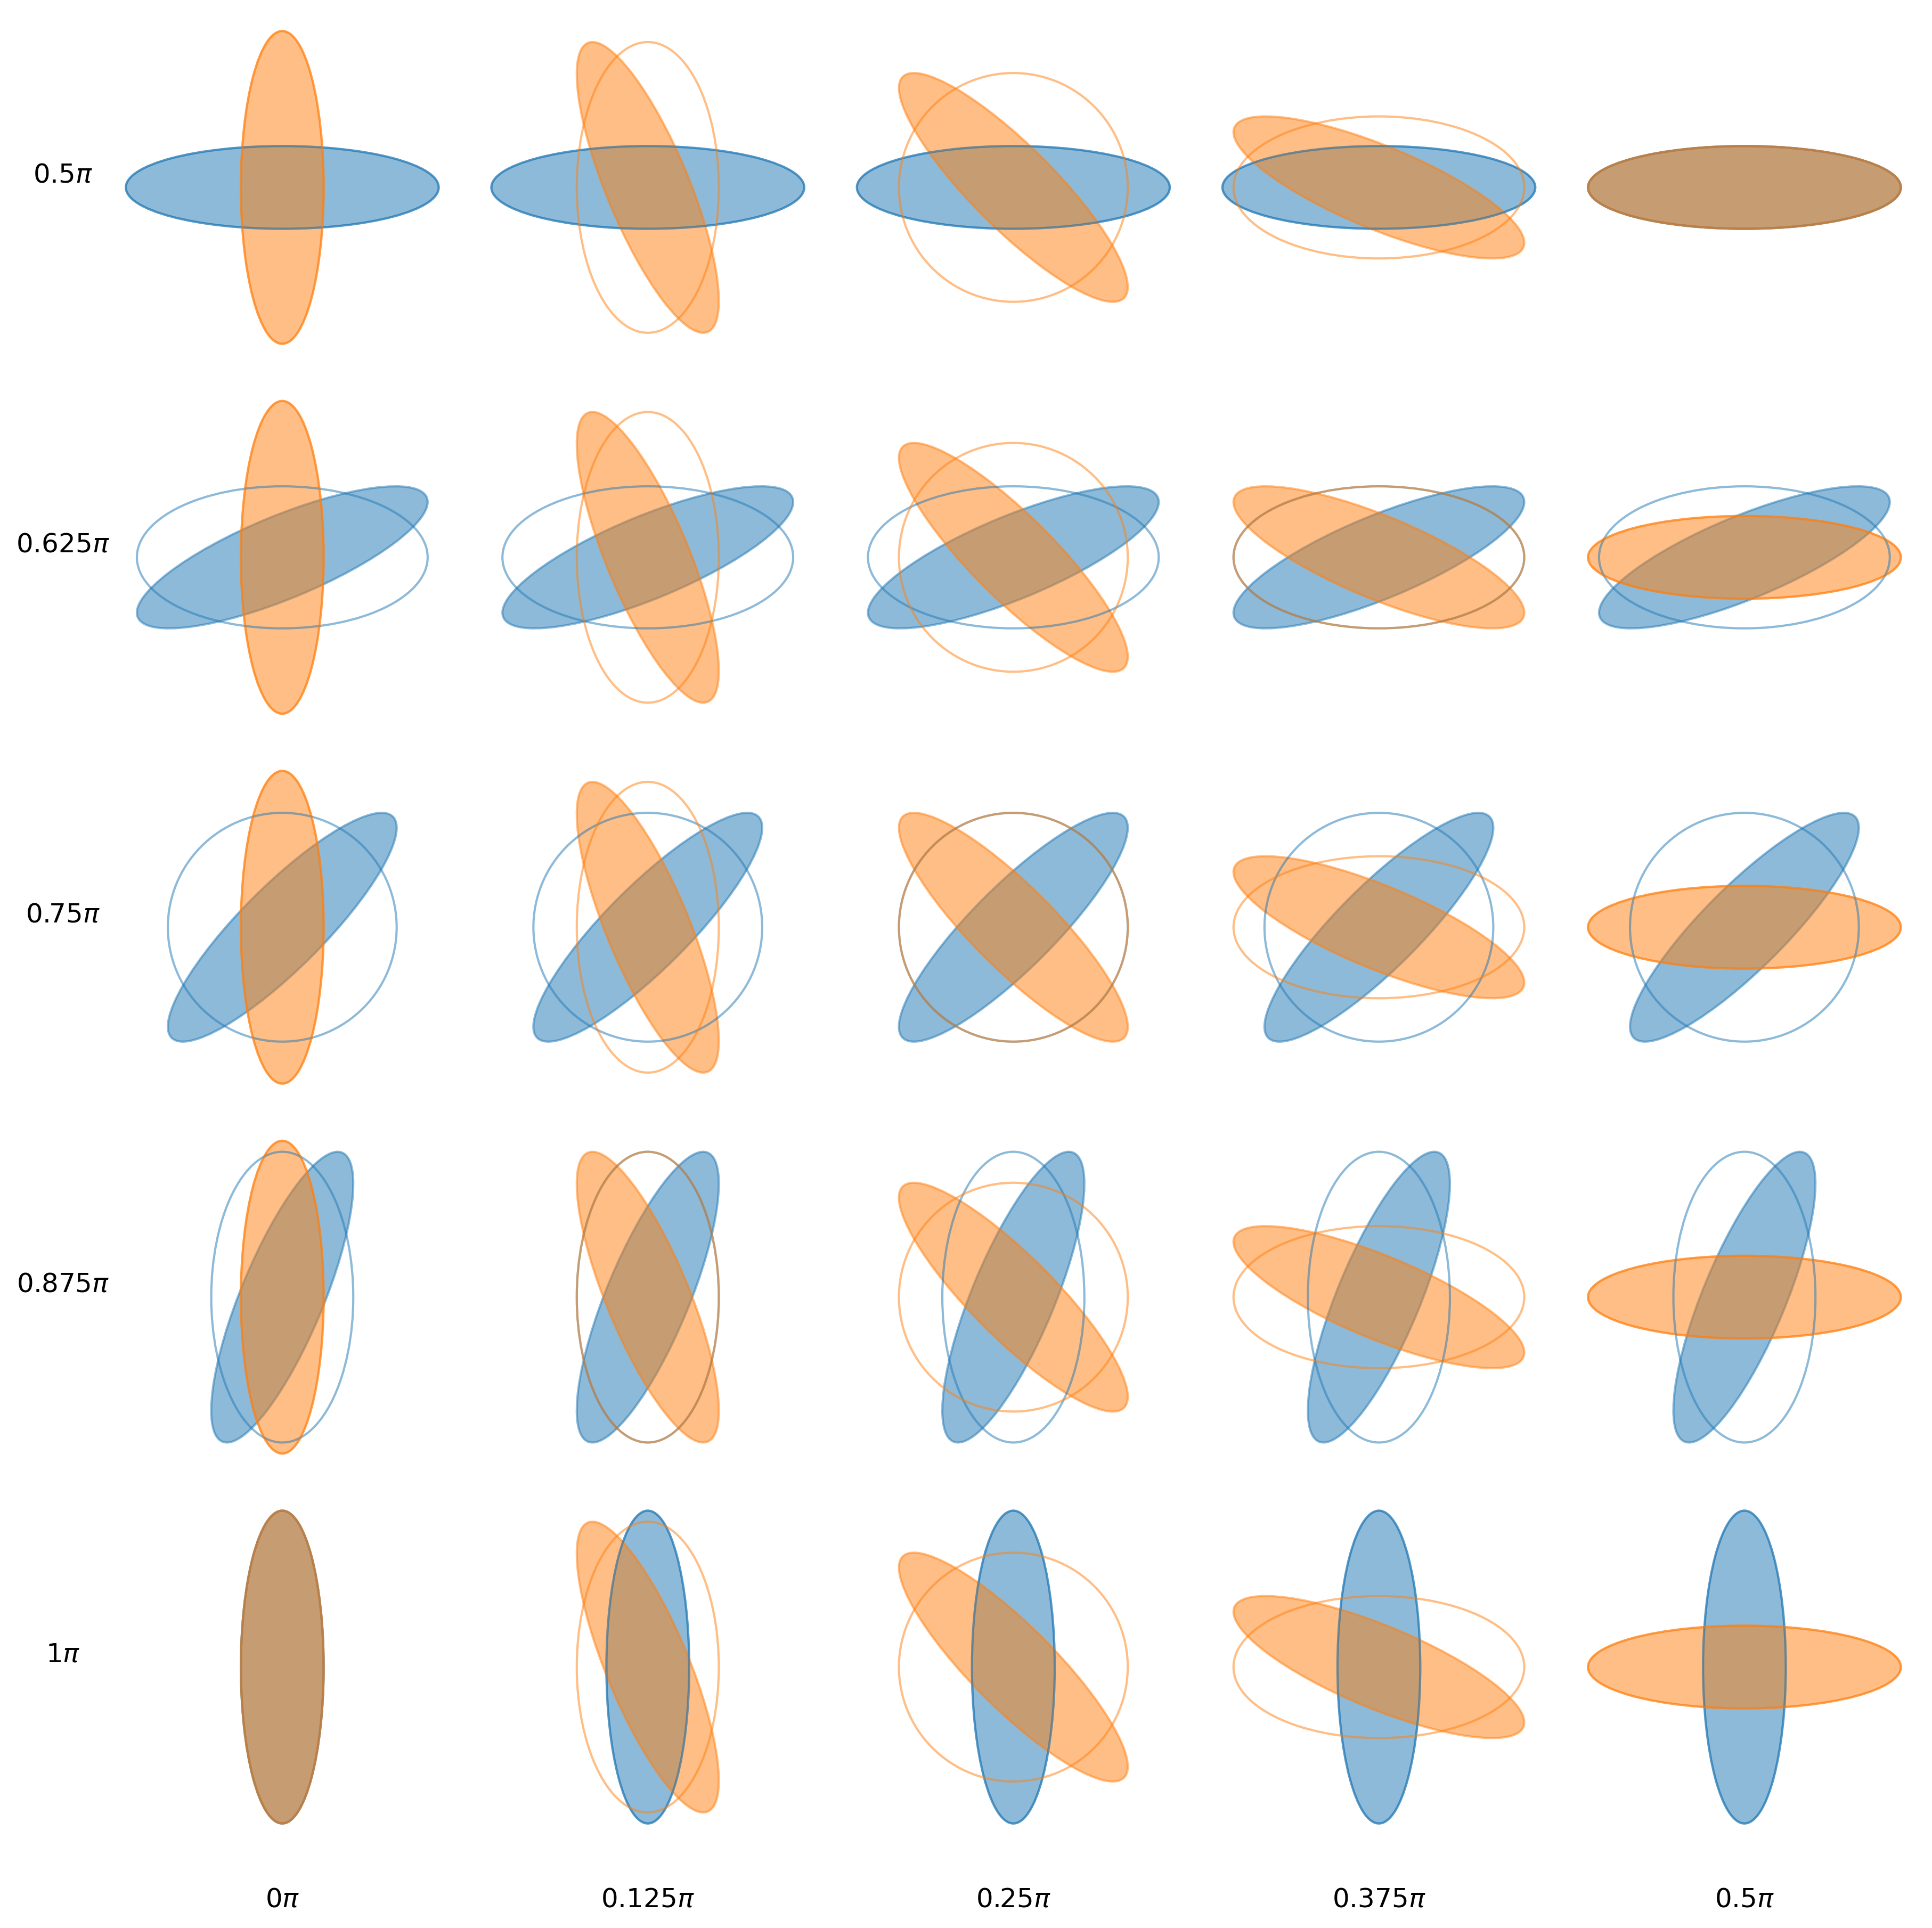

In [4]:
# Compute distances/MI on the (angle1, angle2) grid

fig, axs = plt.subplots(plot_steps + 1, plot_steps + 1, figsize=(3 * plot_steps, 3 * plot_steps))

KLs = np.zeros((steps, steps, 2))
KLs_diag = np.zeros((steps, steps, 2))
EMDs = np.zeros((steps, steps))
EMDs_diag = np.zeros((steps, steps))
EMDs_diag_approx = np.zeros((steps, steps))
cov1s = np.zeros((steps, steps, 2, 2))
cov2s = np.zeros((steps, steps, 2, 2))

gmm_test = create_gmm([cov1, cov2], means=means)
_gmm, groundtruth_emd, KL = compute_gmm_marginals(gmm=gmm_test, plot=False)

for i, angle1 in enumerate(angles):
    for j, angle2 in enumerate(angles):
        rota1 = np.array([[np.cos(angle1), -np.sin(angle1)], [np.sin(angle1), np.cos(angle1)]], dtype=float)
        cov1_rota = rota1 @ cov1 @ rota1.T
        cov1s[i, j, :, :] = cov1_rota

        rota2 = np.array([[np.cos(angle2), -np.sin(angle2)], [np.sin(angle2), np.cos(angle2)]], dtype=float)
        cov2_rota = rota2 @ cov2 @ rota2.T
        cov2s[i, j, :, :] = cov2_rota

        gmm_rota = create_gmm([cov1_rota, cov2_rota], means=means)

        do_snapshot_plot = (i % plot_every_i_step == 0) and (j % plot_every_i_step == 0)
        _gmm, emd, KL1 = compute_gmm_marginals(
            gmm=gmm_rota,
            ax=axs[int(i // plot_every_i_step), int(j // plot_every_i_step)],
            show=False,
            plot=do_snapshot_plot,
            hide_axis=True,
        )
        EMDs[i, j] = emd[0, 1]
        KLs[i, j] = KL1

        gmm_d = diag_gmm(gmm_rota)
        _, emd1, KL2 = compute_gmm_marginals(
            gmm=gmm_d,
            ax=axs[int(i // plot_every_i_step), int(j // plot_every_i_step)],
            show=False,
            fill=False,
            plot=do_snapshot_plot,
            hide_axis=True,
        )
        EMDs_diag[i, j] = emd1[0, 1]
        KLs_diag[i, j] = KL2

        # Diagonal Bures approximation
        _, emd2, _KL3 = compute_gmm_marginals(
            gmm=gmm_rota,
            ax=axs[int(i // plot_every_i_step), int(j // plot_every_i_step)],
            show=False,
            fill=False,
            diag_bures_approx=True,
            plot=False,
        )
        EMDs_diag_approx[i, j] = emd2[0, 1]

# Label snapshot grid axes (same style as original notebook)
angle_labels_x = [r'$' + f'{-1/2 + angle / np.pi:.3g}' + r'\pi$' for k, angle in enumerate(angles) if (k % plot_every_i_step == 0)]
for ax, col in zip(axs[-1], angle_labels_x):
    ax.set_xlabel(col, size='large', labelpad=-30)

angle_labels_y = [r'$' + f'{angle / np.pi:.3g}' + r'\pi$' for k, angle in enumerate(angles) if (k % plot_every_i_step == 0)]
for ax, row in zip(axs[:, 0], angle_labels_y):
    ax.set_ylabel(row, rotation=0, size='large', labelpad=-30)

plt.tight_layout()

if save_figures:
    save_dir.mkdir(parents=True, exist_ok=True)
    out = save_dir / f'rotating_gaussians_grid.pdf'
    fig.savefig(out, dpi=300, bbox_inches='tight')
    print(f'Saved: {out}')

plt.show()

# Numerical hygiene from the original notebook
EMDs[EMDs < 0] = 0

# Actual error of the approximation
actual_error = EMDs - EMDs_diag

## Compute selected bounds on the grid

In [5]:


bounds = {}  # name -> (steps x steps) array

for name in bounds_to_plot:
    if name not in BOUND_FNS:
        raise KeyError(f'Unknown bound {name!r}. Available: {sorted(BOUND_FNS)}')
    bounds[name] = np.zeros((steps, steps))

for i in range(steps):
    for j in range(steps):
        Xi = cov1s[i, j]
        Yj = cov2s[i, j]
        for name in bounds_to_plot:
            bounds[name][i, j] = BOUND_FNS[name](Xi, Yj, A)

## Contour plots

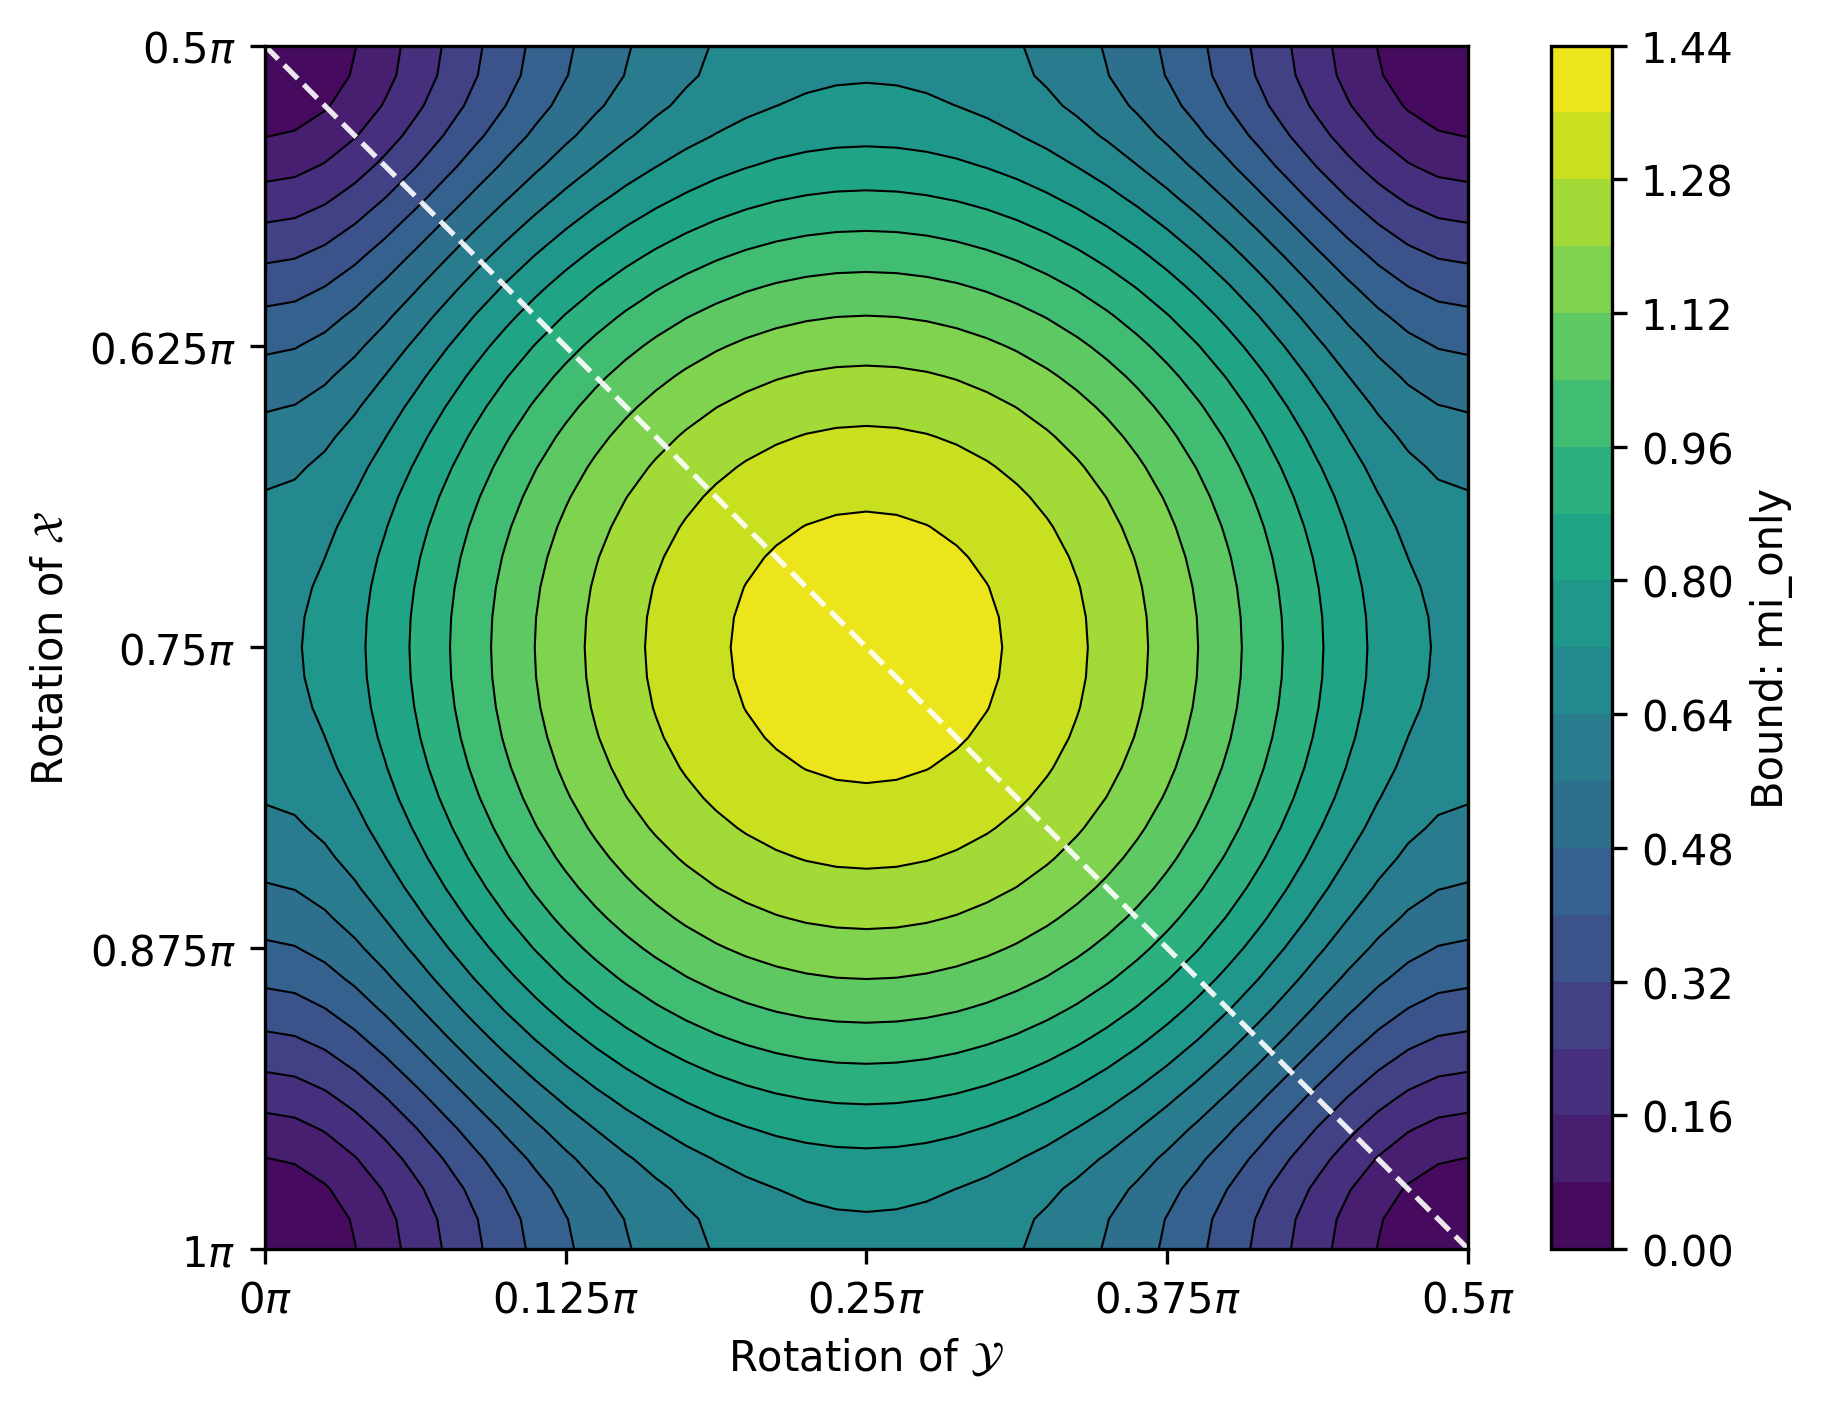

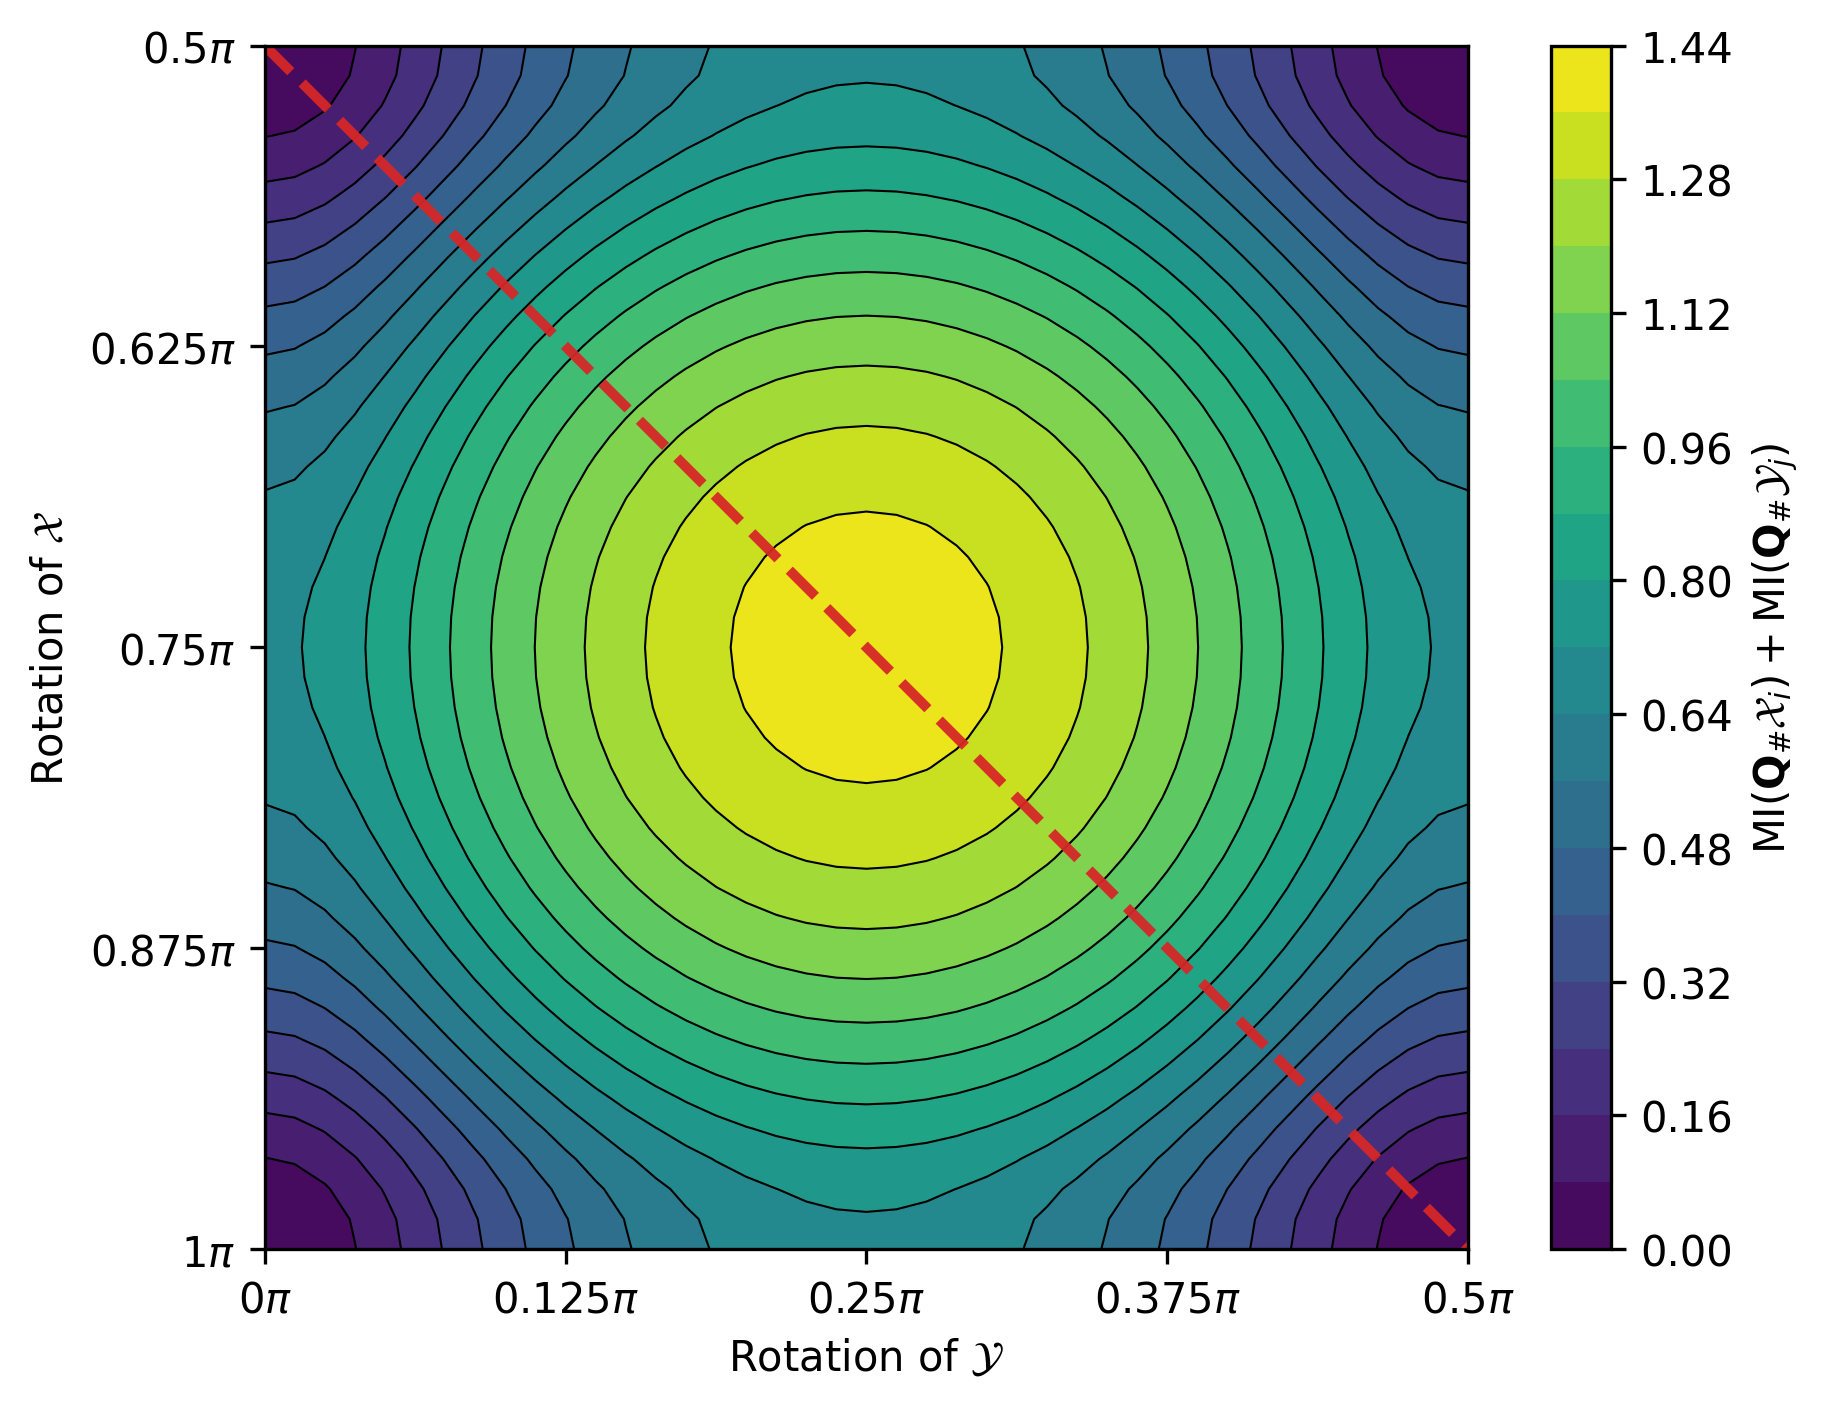

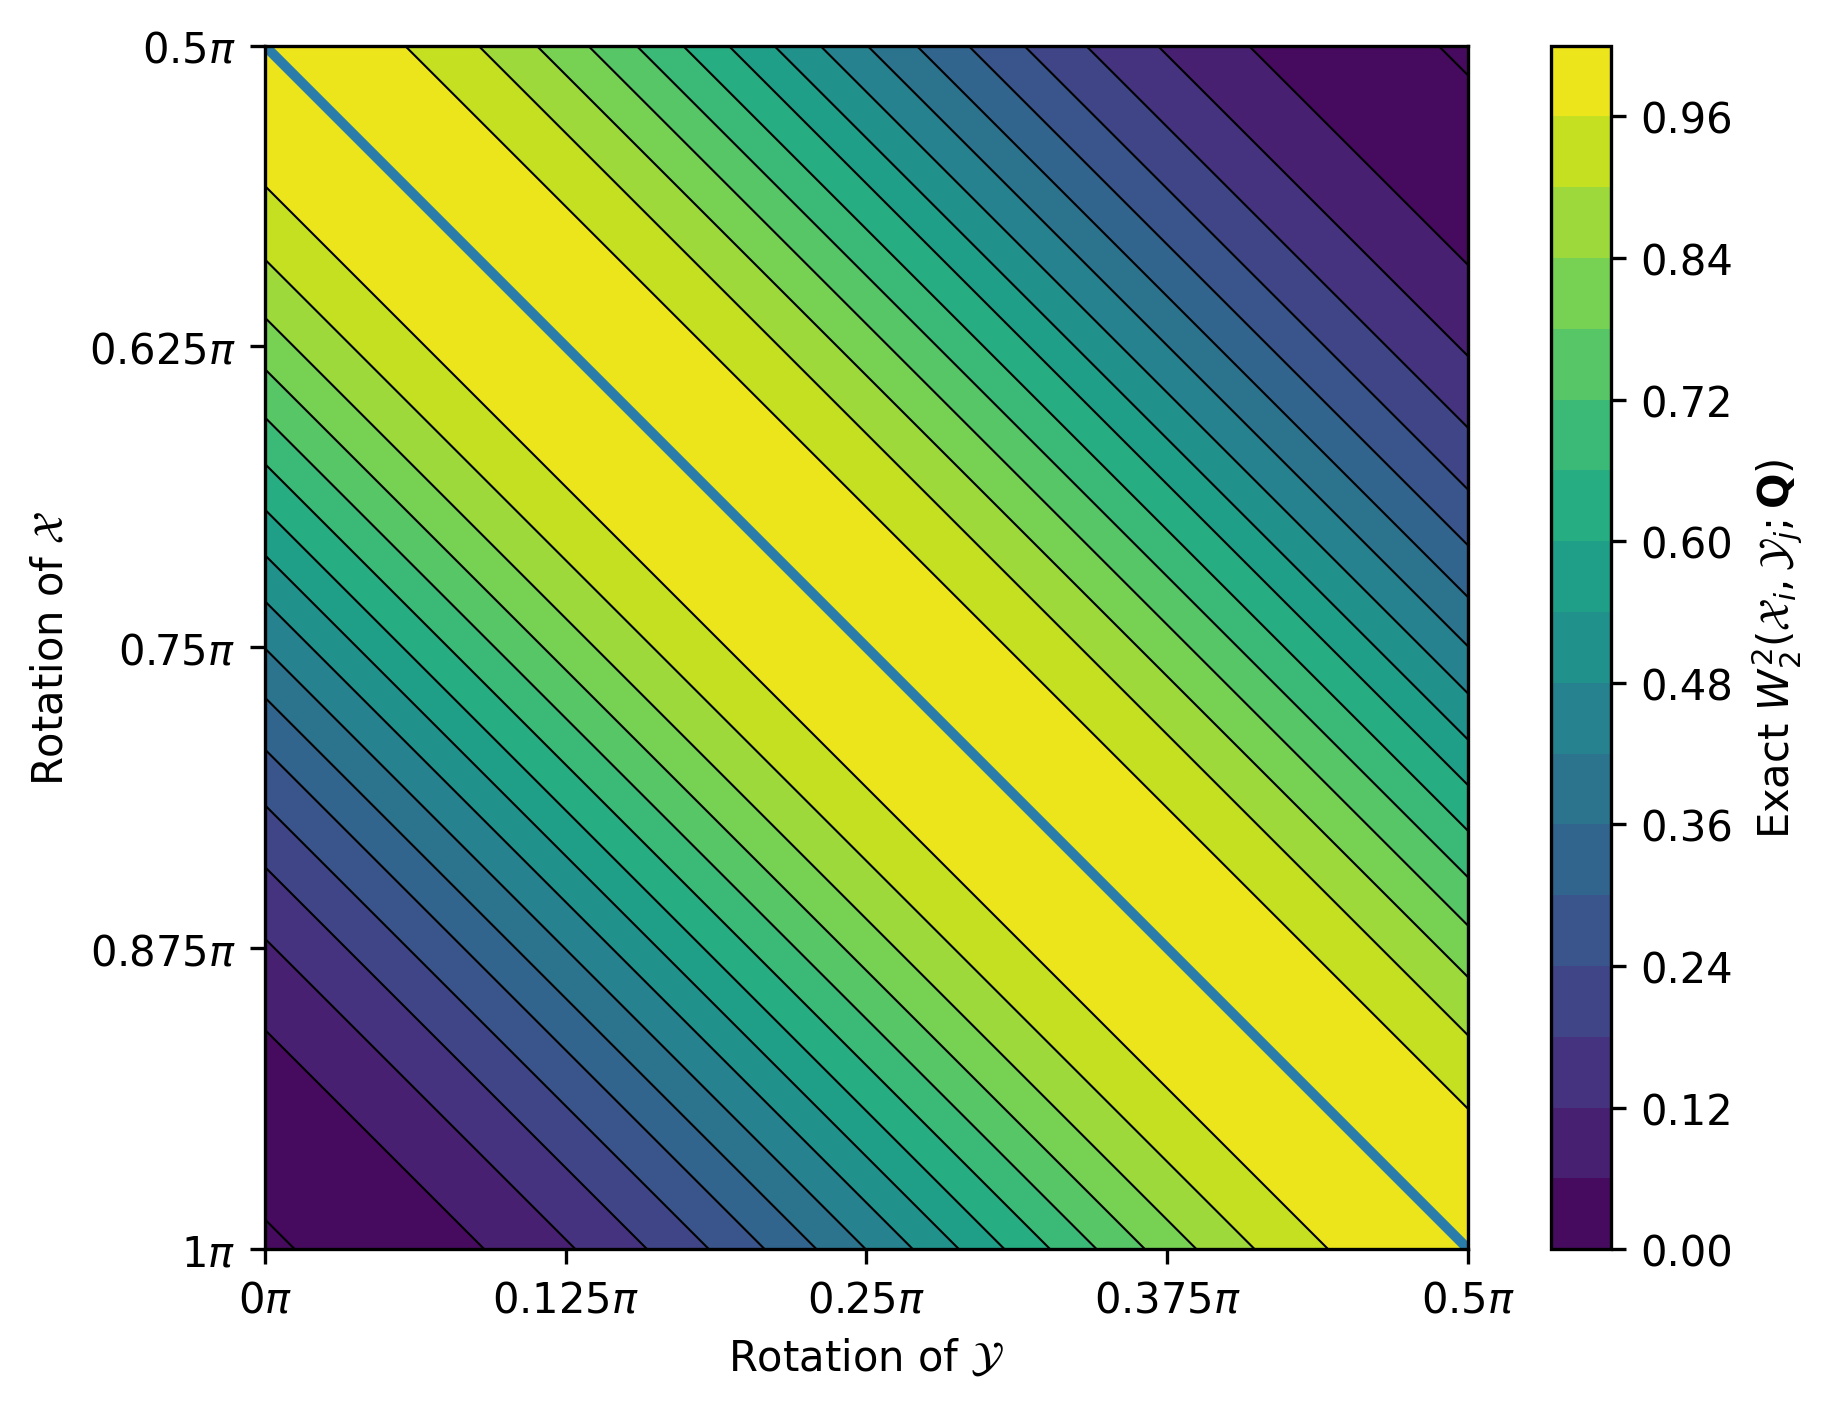

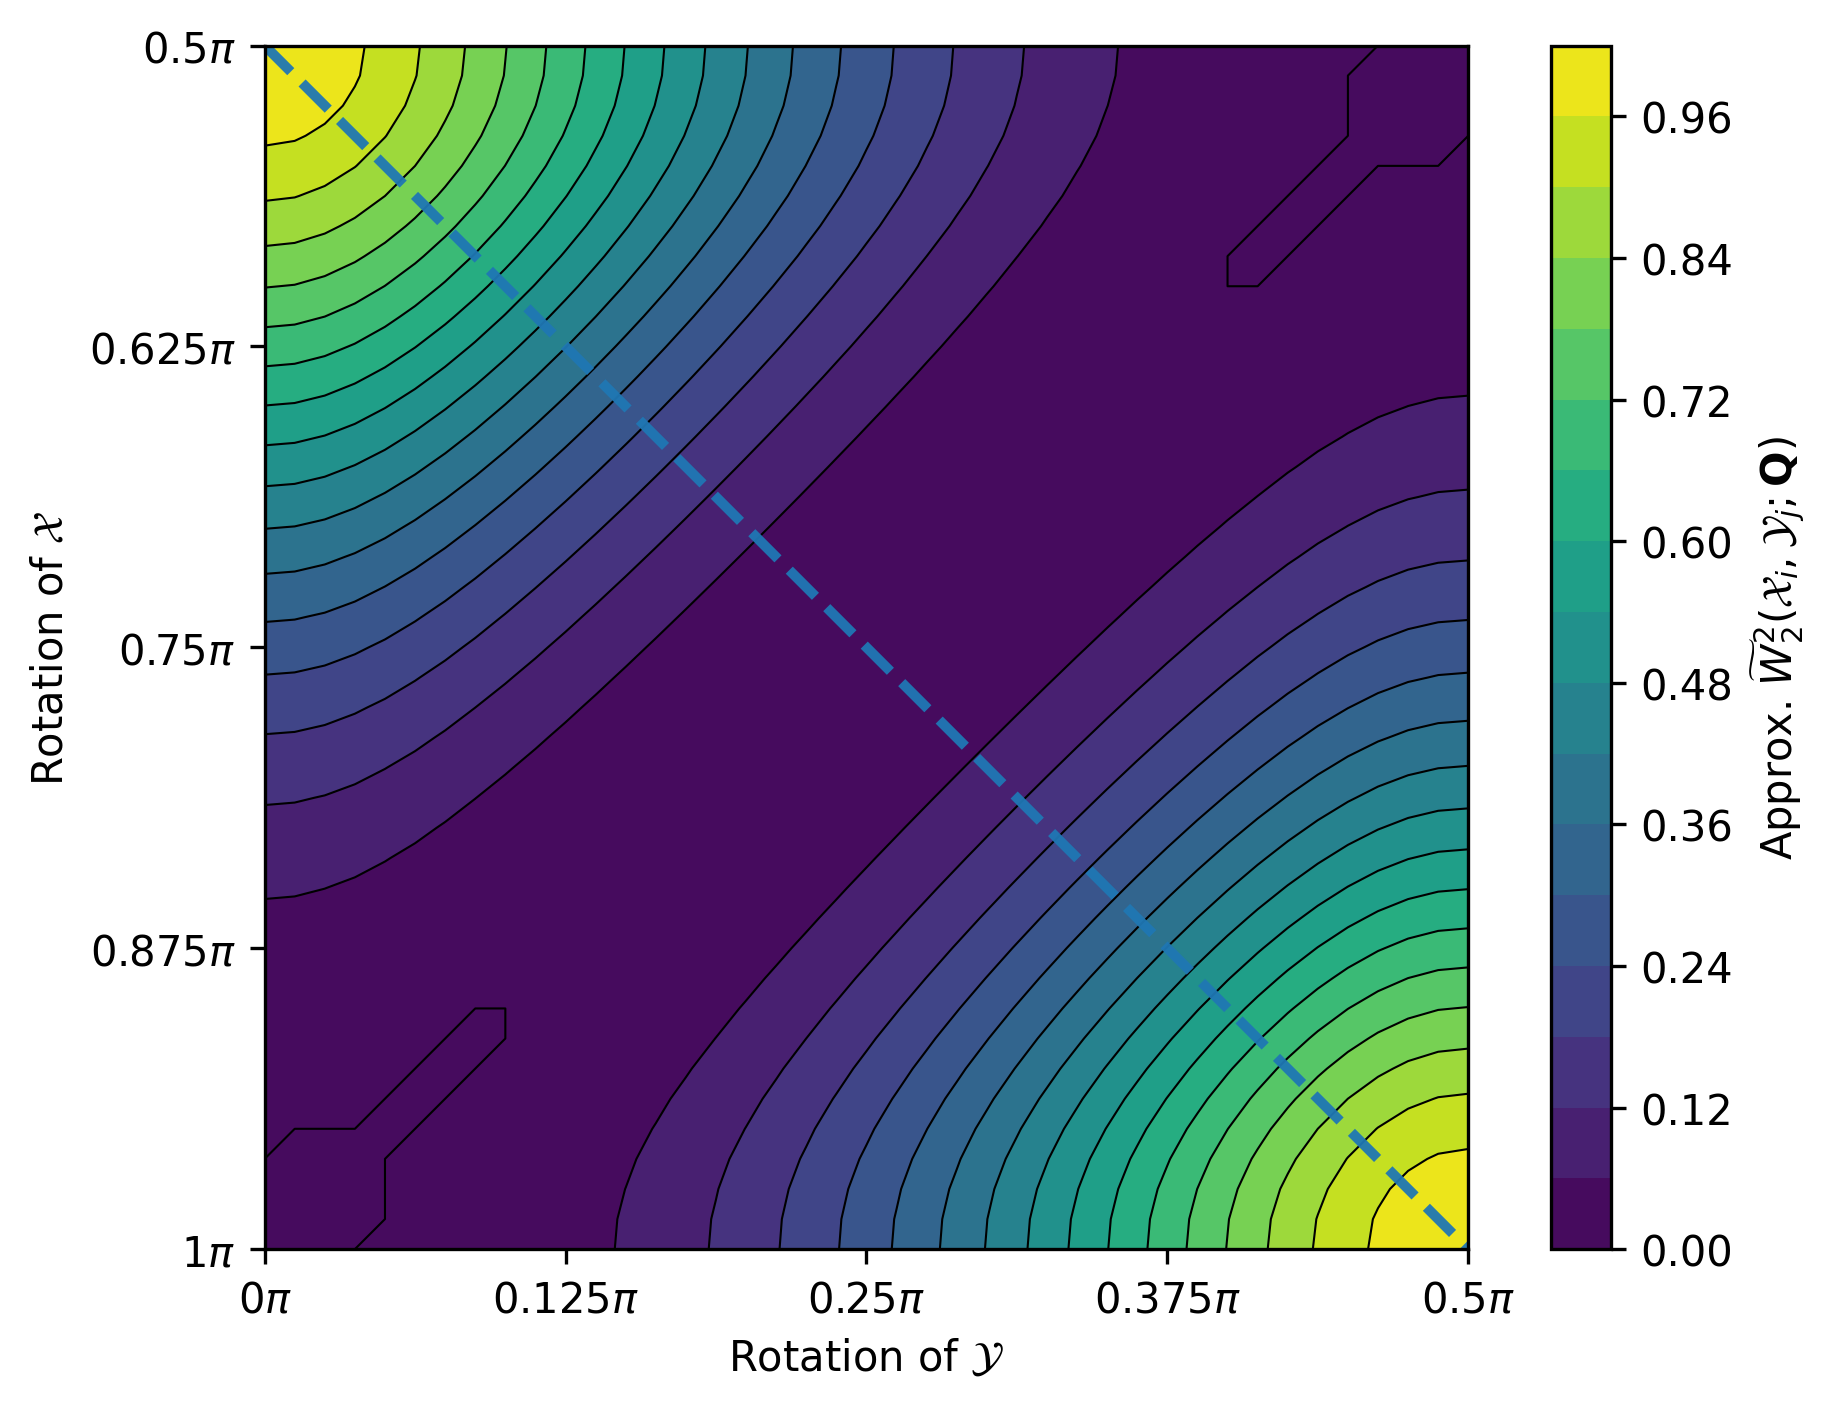

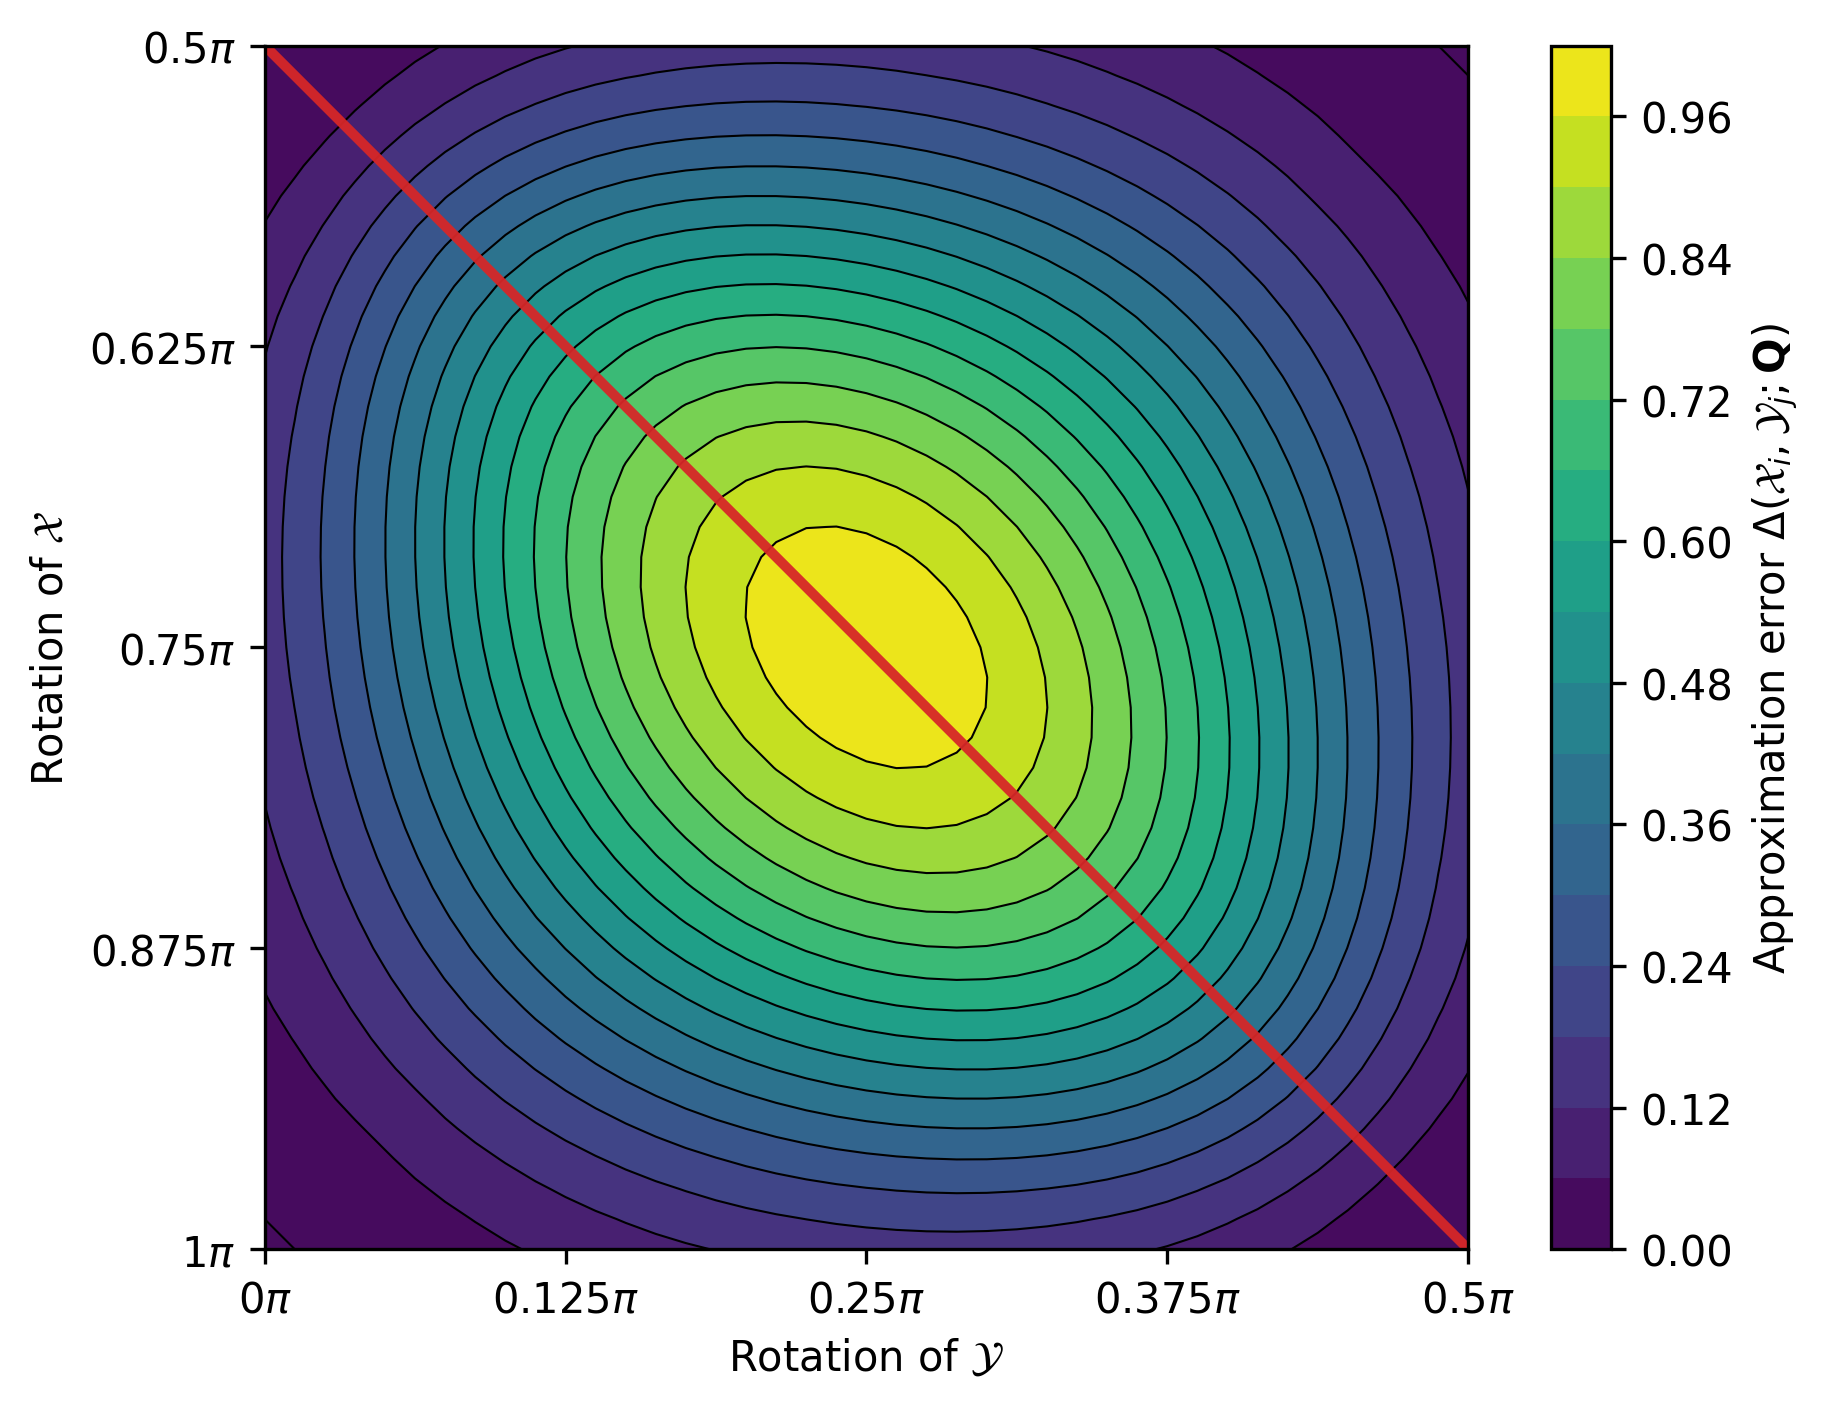

Saved contour plots to: ../data/generated_plots/rotation_bound/0.5pi


In [6]:


angle_strs_x = [-1 / 2 + angle / np.pi for angle in angles]
angle_strs_y = [angle / np.pi for angle in angles]

if save_figures:
    save_dir.mkdir(parents=True, exist_ok=True)

for name in bounds_to_plot:
    contour(
        angle_strs_x,
        angle_strs_y,
        bounds[name],
        cbar_title=f'Bound: {name}',
        axis_label='Rotation of',
        ticks_pi=True,
        save_path=(save_dir / f'contour_bound_{name}.pdf') if save_figures else None,
    )

contour(
    angle_strs_x,
    angle_strs_y,
    np.sum(KLs, axis=-1),
    cbar_title=r'$\mathrm{MI}(\mathbf{Q}_{\#}\mathcal{X}_i) + \mathrm{MI}(\mathbf{Q}_{\#}\mathcal{Y}_j)$',
    axis_label='Rotation of',
    ticks_pi=True,
    diag_line_kwargs={'linestyle': '--', 'linewidth': 2.4, 'alpha': 0.95, 'color': 'tab:red'},
    save_path=(save_dir / f'contour_MI_sum.pdf') if save_figures else None,
)

contour(
    angle_strs_x,
    angle_strs_y,
    EMDs,
    cbar_title=r'Exact $W_2^2(\mathcal{X}_i, \mathcal{Y}_j; \mathbf{Q})$',
    axis_label='Rotation of',
    ticks_pi=True,
    diag_line_kwargs={'linestyle': '-', 'linewidth': 2.4, 'alpha': 0.95, 'color': 'tab:blue'},
    save_path=(save_dir / f'contour_W_joint.pdf') if save_figures else None,
)

contour(
    angle_strs_x,
    angle_strs_y,
    EMDs_diag, #_approx,
    cbar_title=r'Approx. $\widetilde{W}_2^2(\mathcal{X}_i, \mathcal{Y}_j; \mathbf{Q})$',
    axis_label='Rotation of',
    ticks_pi=True,
    diag_line_kwargs={'linestyle': '--', 'linewidth': 2.4, 'alpha': 0.95, 'color': 'tab:blue'},
    save_path=(save_dir / f'contour_W_diag_approx.pdf') if save_figures else None,
)

contour(
    angle_strs_x,
    angle_strs_y,
    actual_error,
    cbar_title=r'Approximation error $\Delta(\mathcal{X}_i, \mathcal{Y}_j; \mathbf{Q})$',
    axis_label='Rotation of',
    ticks_pi=True,
    diag_line_kwargs={'linestyle': '-', 'linewidth': 2.4, 'alpha': 0.95, 'color': 'tab:red'},
    save_path=(save_dir / f'contour_error_diag_approx.pdf') if save_figures else None,
)

if save_figures:
    print(f'Saved contour plots to: {save_dir}')

## Diagonal comparison plot (line plot along angle1 == angle2)

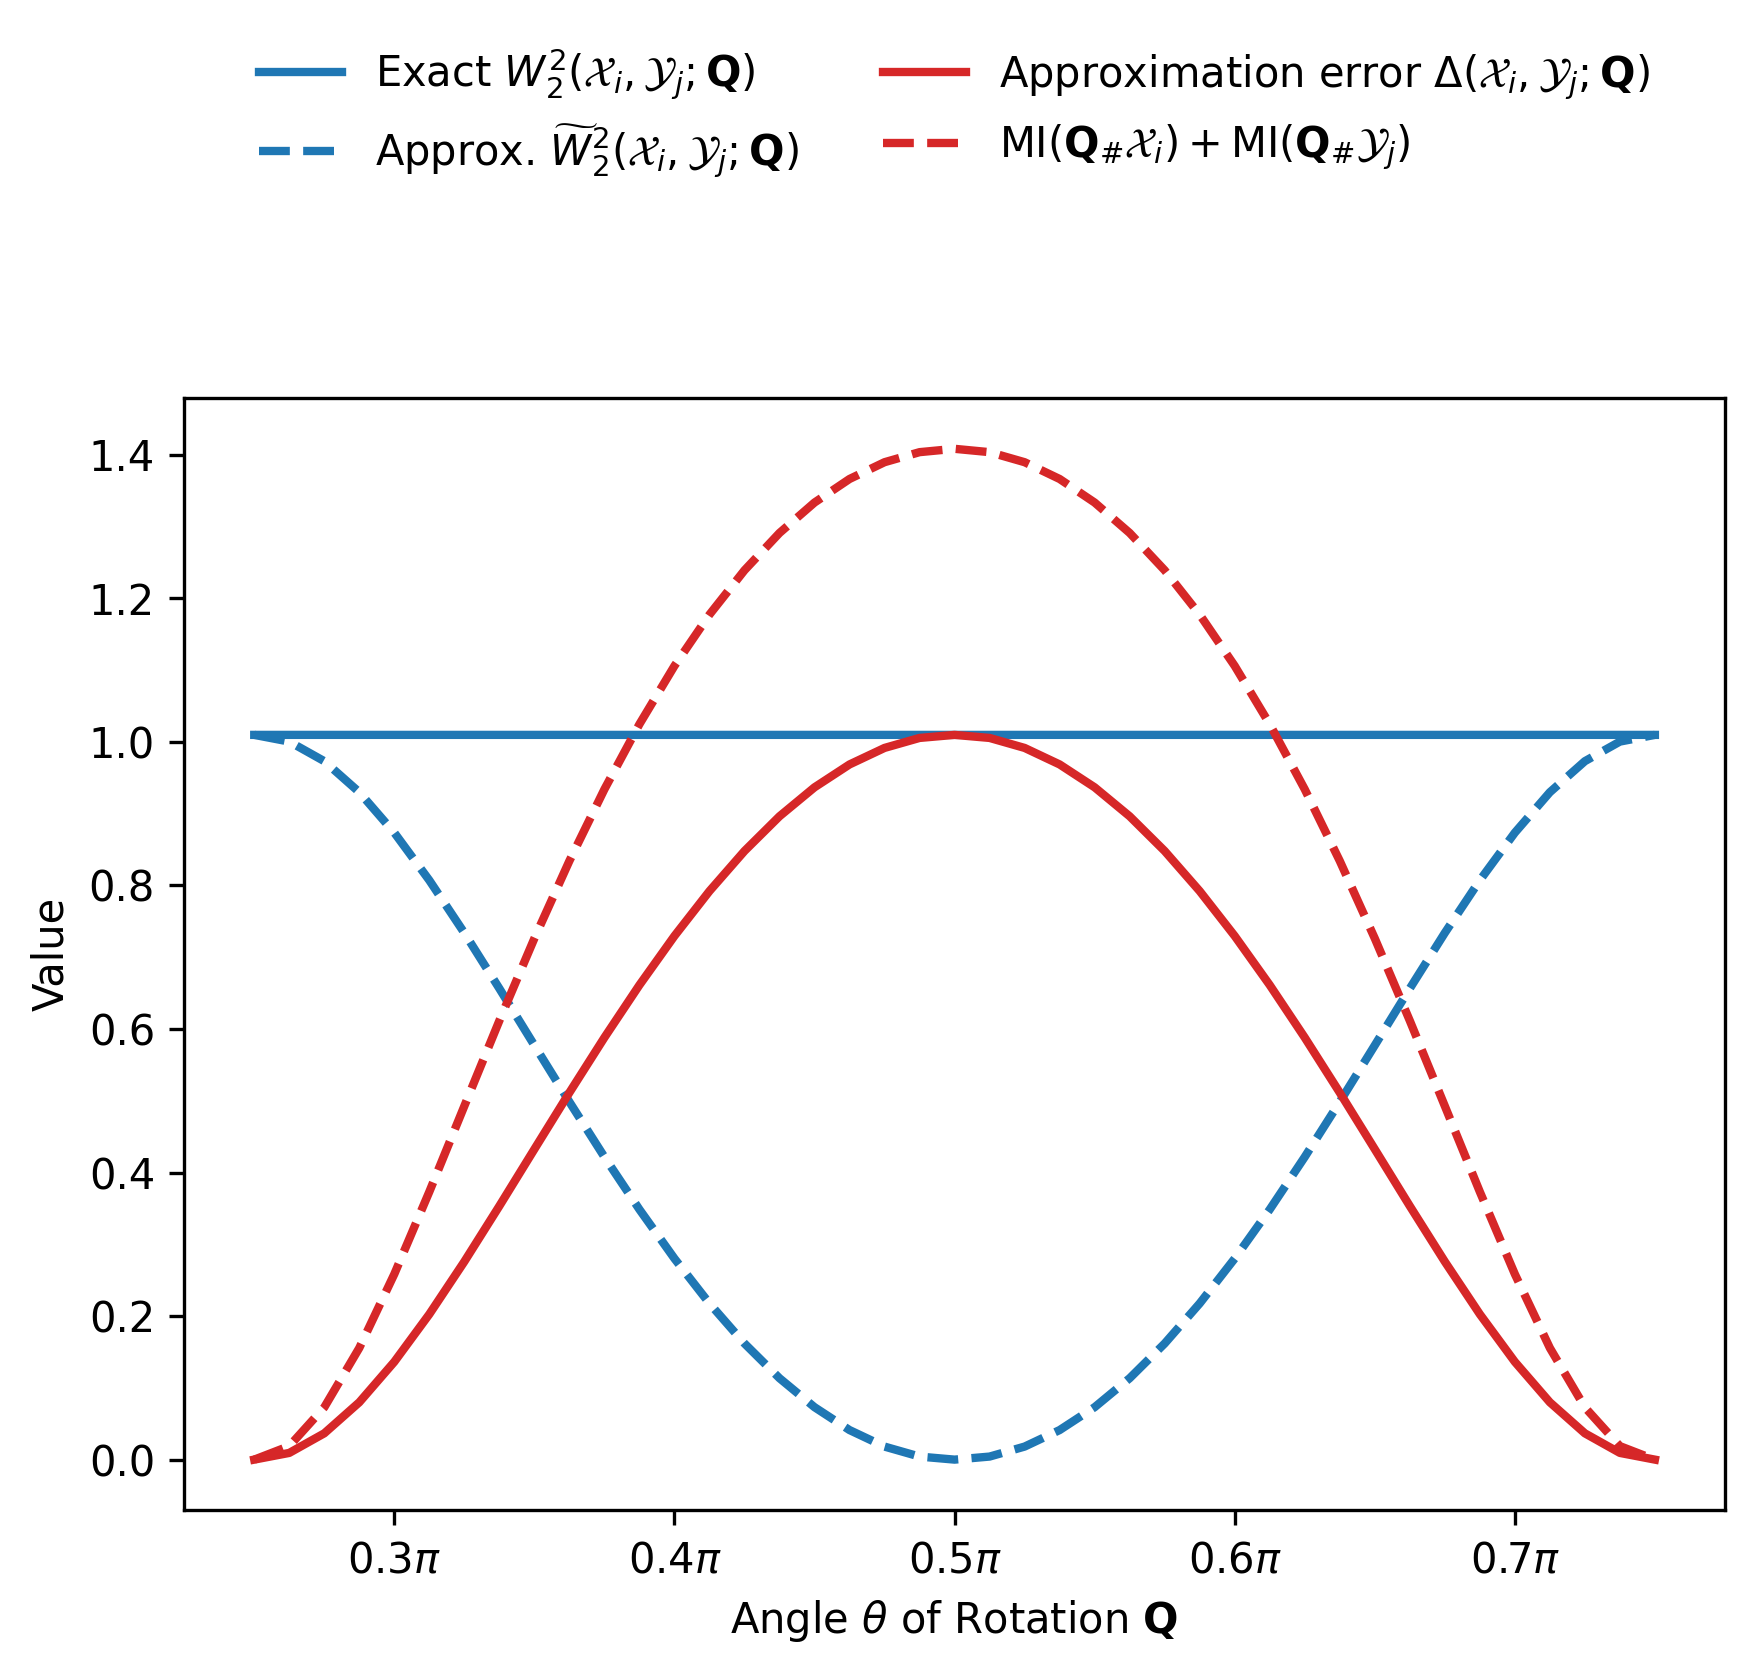

Saved: ../data/generated_plots/rotation_bound/0.5pi/rotation_influence_2D_bounds.pdf


In [7]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.set_xlabel(r'Angle $\theta$ of Rotation $\mathbf{Q}$')
ax.set_ylabel('Value')

lines = []

lines.append(
    contour_diag(
        angle_strs_x,
        angle_strs_y,
        EMDs,
        cbar_title=r'Exact $W_2^2(\mathcal{X}_i, \mathcal{Y}_j; \mathbf{Q})$',
        ticks_pi=True,
        ax=ax,
        fig=fig,
        line_fmt={'linestyle': '-', 'linewidth': 2, 'color': 'tab:blue'},
    )
)
lines.append(
    contour_diag(
        angle_strs_x,
        angle_strs_y,
        EMDs_diag, #_approx,
        cbar_title=r'Approx. $\widetilde{W}_2^2(\mathcal{X}_i, \mathcal{Y}_j; \mathbf{Q})$',
        ticks_pi=True,
        ax=ax,
        fig=fig,
        line_fmt={'linestyle': '--', 'linewidth': 2, 'color': 'tab:blue'},
    )
)

lines.append(
    contour_diag(
        angle_strs_x,
        angle_strs_y,
        actual_error,
        cbar_title=r'Approximation error $\Delta(\mathcal{X}_i, \mathcal{Y}_j; \mathbf{Q})$',
        ticks_pi=True,
        ax=ax,
        fig=fig,
        line_fmt={'linestyle': '-', 'linewidth': 2, 'color': 'tab:red'},
    )
)

for name in bounds_to_plot:
    lines.append(
        contour_diag(
            angle_strs_x,
            angle_strs_y,
            bounds[name],
            cbar_title=r'$\mathrm{MI}(\mathbf{Q}_{\#}\mathcal{X}_i) + \mathrm{MI}(\mathbf{Q}_{\#}\mathcal{Y}_j)$',
            ticks_pi=True,
            ax=ax,
            fig=fig,
            line_fmt={'linestyle': '--', 'linewidth': 2, 'color': 'tab:red'},
        )
    )


formatter = plticker.FuncFormatter(pi_formatter)
ax.xaxis.set_major_formatter(formatter)

ax.legend(handles=lines, loc='upper center', bbox_to_anchor=(0.5, 1.35), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

if save_figures:
    save_dir.mkdir(parents=True, exist_ok=True)
    out = save_dir / f'rotation_influence_2D_bounds.pdf'
    fig.savefig(out, dpi=300)
    print(f'Saved: {out}')